# Práctica de Presión
***

*Ismael Darias Darias* &emsp;&emsp; *Máster en Geofísica y Meteorología*

*Instrumentación en geofísica y meteorología (meteorología)* &emsp;&emsp; *Universidad de Granada*

En este notebook se desarrolla el código empleado para la práctica de presión. Está práctica consiste en calibrar un barómetro mediante medidas de un barómetro considerado de referencia.

Para el barómetro B2, el fabricador especifica que el método para calcular la presión a través del voltaje es:

$P = \frac{P_{range}}{V_{range}}V + P_{low}$

donde P es la presión, $P_{low}$ es el límite inferior del rango de presión, $P_{range}$ es el rango de presión, $V_{range}$ es el rango del voltaje y V es el voltaje de salida de la medida.

Para el caso concreto dado se indica que el rango de presión va desde los 500 hasta los 1100 hPa y el voltaje de 0 a 2.5 V.

Para realizar la práctica se siguen los siguientes pasos:
1. Visualización de los datos.
2. Cálculo de la presión de B2 empleando la fórmula anterior.
3. Emplear un ajuste por mínimos cuadrados para calcular las constantes de calibración m y b para B1.
4. Calcular el error relativo medio en % para la serie de datos de B1, empleando: $\frac{P_{medido} - P_{patron}}{P_{patron}}$

In [1]:
# Importamos librerias a usar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Visualización de los datos

In [2]:
df = pd.read_excel('presion.xlsx')
df.head()

,B1 (V),B2 (V)
0,1.869565,1.845971
1,1.869565,1.846050
2,1.869837,1.846062
3,1.869875,1.845833
4,1.869897,1.846142


Podemos observar que son 2 columnas simples con las medidas de voltaje. Por lo tanto, no es necesario hacer ningún tipo de operación más que las indicadas en el procedimiento.

In [3]:
# Extraemos series
B1 = df['B1 (V)']
B2 = df['B2 (V)']

## Calculo de la presión B2

Empleando la serie extraida y la ecuación del fabricante, la presión se puede calcular de forma sencilla

In [4]:
# Parametros de la ecuacion
Plow = 500 # hPa
Prange = 1100 - 500 #hPa
Vrange = 2.5 # V

# Calculamos serie
P2 = (Prange / Vrange) * B2 + Plow

## Ajuste por mínimos cuadrados de la presión y el voltaje

Ajustamos la presión con el voltaje y representamos para extraer las constantes de calibración.

In [5]:
m, b = np.polyfit(B1, P2, 1)

In [10]:
print(f'Pendiente: {m:.3f} hPa/V \n Término independiente: {b:.3f} hPa')

Pendiente: 183.645 hPa/V 
 Término independiente: 599.640 hPa


A partir de aquí podemos obtener el patrón de presión que usamos como referencia, empleando los coeficientes. Para ello, definimos una función

In [7]:
def Ppatron(M, B, V):
    return M * V + B

Representamos ahora el ajuste y los datos para ver que tan bueno es el ajuste

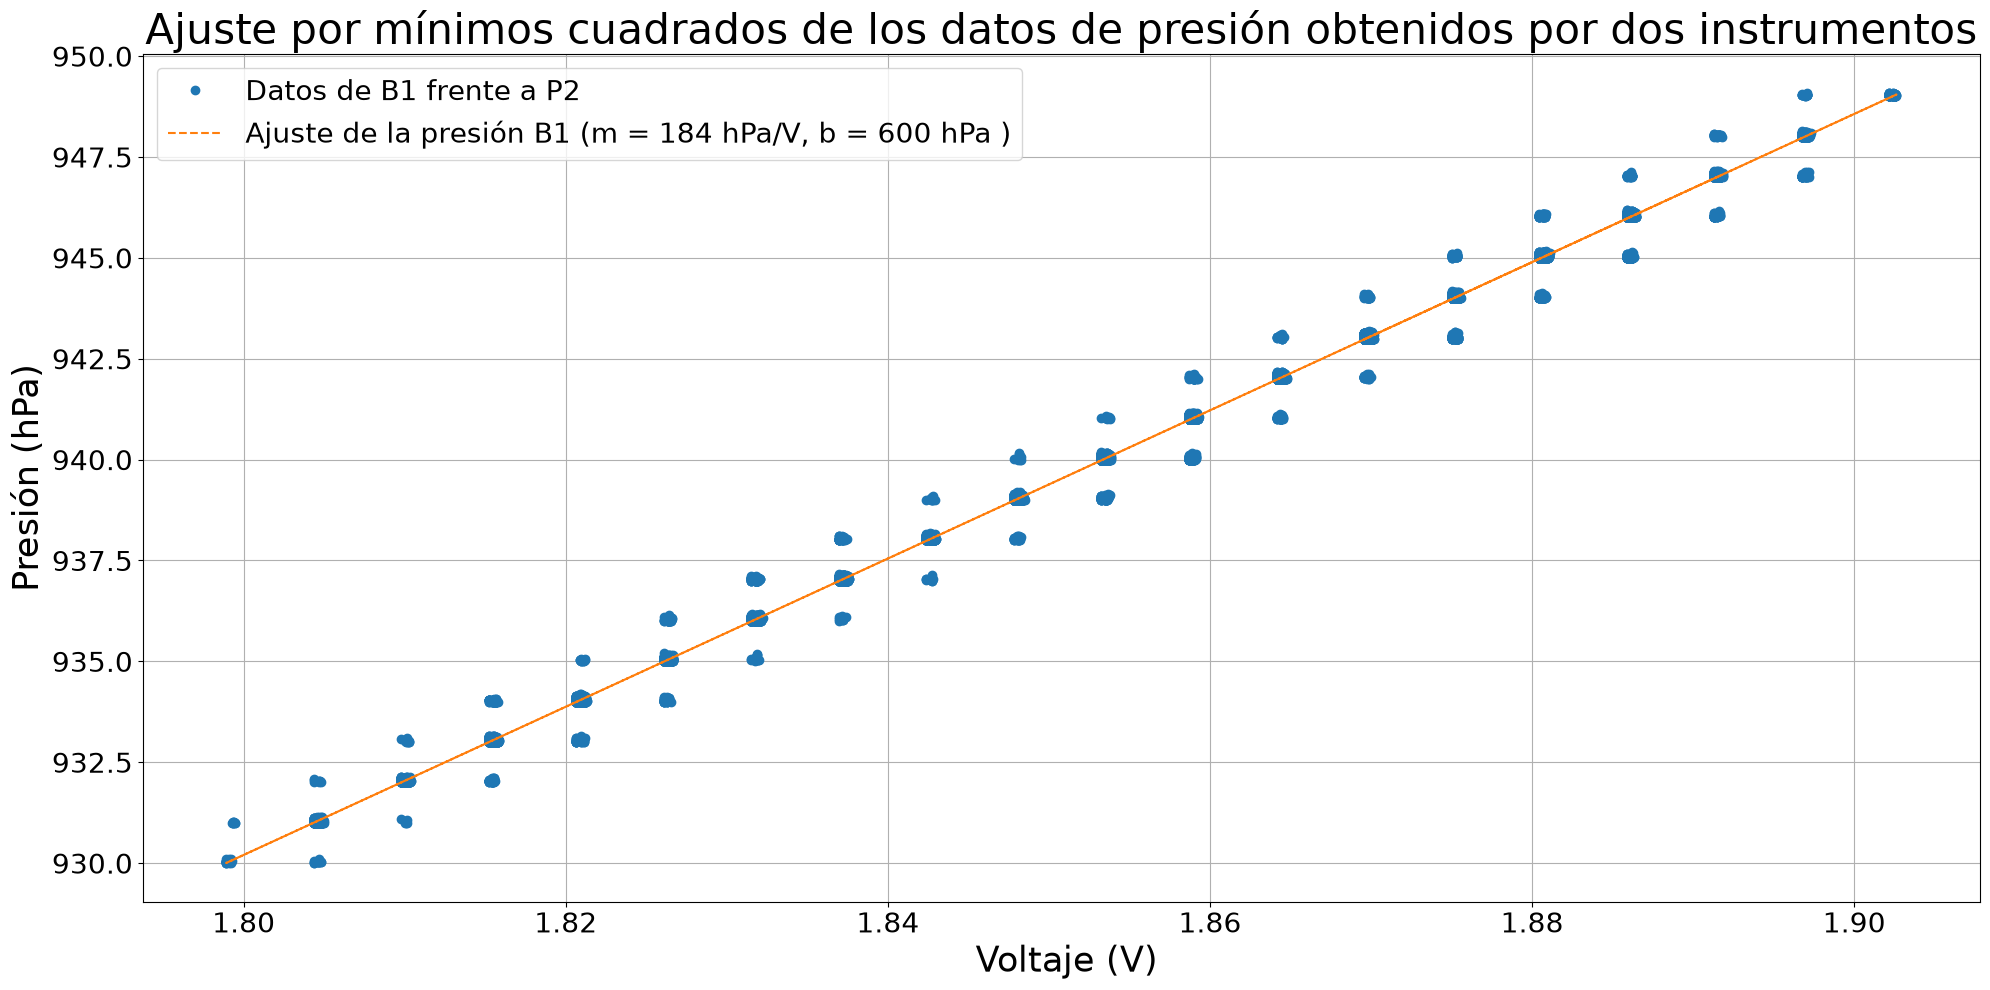

In [8]:
fig, ax = plt.subplots(figsize = (20, 10))

ax.plot(B1, P2, 'o', label = 'Datos de B1 frente a P2')
ax.plot(B1, Ppatron(m, b, B1), '--', label = f'Ajuste de la presión B1 (m = {m:.3g} hPa/V, b = {b:.3g} hPa )')

ax.set_title('Ajuste por mínimos cuadrados de los datos de presión obtenidos por dos instrumentos', fontsize = 30)
ax.set_xlabel(' Voltaje (V)', fontsize = 25)
ax.set_ylabel('Presión (hPa)', fontsize = 25)
ax.legend(loc = 'best', fontsize = 20)
ax.grid()

ax.tick_params(axis='both', labelsize=20)
plt.tight_layout()

plt.savefig('./Images/ajuste.png')
plt.show()


## Calculo del error relativo

El error relativo se puede calcular de forma sencilla asumiento que la serie de datos obtenida del patrón es perfecta. De esta forma calculamos el error en cada punto como: $\frac{P_{medido}-P_{patron}}{P_{patron}}$

In [12]:
# Presión del patrón
Pmedida = Ppatron(m, b, B1)

er = abs((Pmedida - P2) * 100 / P2)

er_medio = np.mean(er)
er_desv = np.std(er)

print(rf'El error medio es de {er_medio:.2g} $\pm$ {er_desv:.2g} %')

El error medio es de 0.0084 $\pm$ 0.022 %


Vemos que el error puede llegar a ser de 0.03 hPa, lo que equivale a un error de la presión entorno a los 3 Pascales, lo cual indica que la calibración es lo suficientemente buena como para ser considerada en futuras mediciones.